<a href="https://colab.research.google.com/github/HeyWinTomsy/MN/blob/main/%D0%9B%D0%A010_%D0%90%D0%BD%D1%82%D1%80%D0%BE%D0%BF%D0%BE%D0%B2_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Антропов Назар

**Група:** ФІТ 3-10  
**Дата:** 20.11.26

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [23]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import classification_report

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [24]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'T-shirt/top',
    'Trouser',
    'Pullover',
    'Dress',
    'Coat',
    'Sandal',
    'Shirt',
    'Sneaker',
    'Bag',
    'Ankle boot'
]

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

print("\nКількість класів:", len(class_names))

x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)

Кількість класів: 10


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

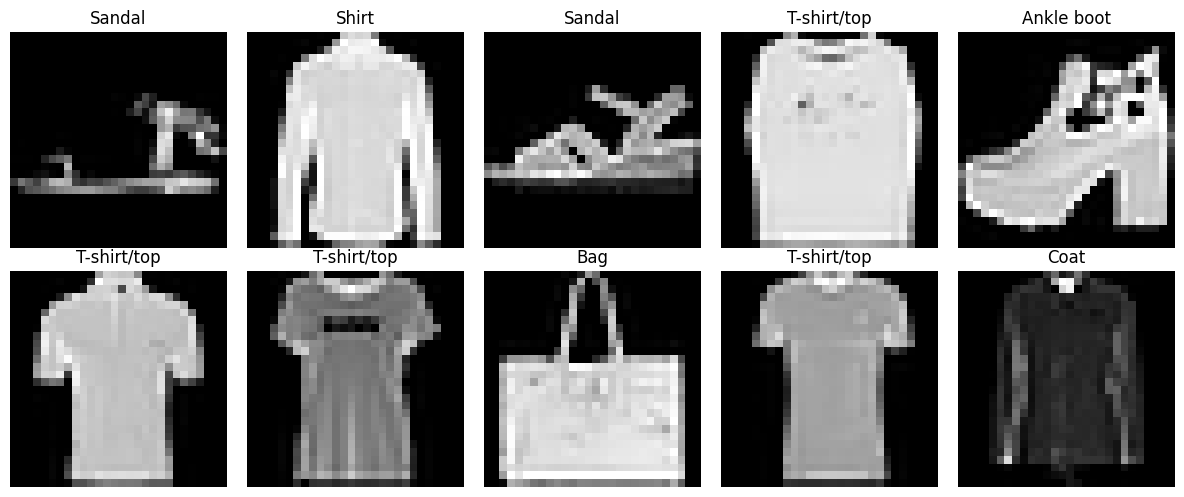

In [25]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(12, 5))

indices = np.random.choice(len(x_train), 10, replace=False)

for i, idx in enumerate(indices):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_train[idx], cmap='gray')
    plt.title(class_names[y_train[idx]])
    plt.axis('off')

plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [26]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Мінімальне значення:", x_train.min())
print("Максимальне значення:", x_train.max())

print("Тип даних:", x_train.dtype)

Мінімальне значення: 0.0
Максимальне значення: 1.0
Тип даних: float32


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [27]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),

    layers.Flatten(),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),

    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Модель успішно створена!")

Модель успішно створена!


### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [ ]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history = model.fit(
    x_train,
    y_train,
    epochs=30,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.7771 - loss: 0.6261 - val_accuracy: 0.8457 - val_loss: 0.4135 - learning_rate: 0.0010
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8440 - loss: 0.4311 - val_accuracy: 0.8625 - val_loss: 0.3817 - learning_rate: 0.0010
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8566 - loss: 0.3960 - val_accuracy: 0.8705 - val_loss: 0.3577 - learning_rate: 0.0010
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8667 - loss: 0.3659 - val_accuracy: 0.8716 - val_loss: 0.3479 - learning_rate: 0.0010
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8696 - loss: 0.3530 - val_accuracy: 0.8809 - val_loss: 0.3351 - learning_rate: 0.0010
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8750 - loss: 0.3387 - val_accuracy: 0.8799 - val_loss: 0.3290 - learning_rate: 0.0010
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8794 - loss: 0.3253

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [ ]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()

print("\nКількість шарів:", len(model.layers))

print("Загальна кількість параметрів:", model.count_params())

### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [ ]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
model.save('fashion_mnist_model.keras')

print("Модель збережено!")

from google.colab import drive

drive.mount('/content/drive')

model.save('/content/drive/MyDrive/fashion_mnist_model.keras')

print("Модель збережено на Google Drive!")

### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

In [ ]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [ ]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

y_pred_prob = model.predict(x_test)

y_pred = np.argmax(y_pred_prob, axis=1)

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))

if test_accuracy >= 0.87:
    print("Цільову точність 0.87 досягнуто!")
else:
    print("Цільову точність 0.87 не досягнуто.")

### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

In [ ]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(15, 6))

indices = np.random.choice(len(x_test), 10, replace=False)

for i, idx in enumerate(indices):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[idx], cmap='gray')

    true_label = class_names[y_test[idx]]
    predicted_label = class_names[y_pred[idx]]

    color = 'green' if y_test[idx] == y_pred[idx] else 'red'

    plt.title(
        f"True: {true_label}\nPredicted: {predicted_label}",
        color=color,
        fontsize=9
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
_..._

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [ ]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip install -q keras-tuner
import keras_tuner as kt

from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import numpy as np
import matplotlib.pyplot as plt

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [ ]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
print("x_train:", x_train.shape)
print("y_train:", y_train.shape)

print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

print("\nДіапазон значень:", x_train.min(), "-", x_train.max())

### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [ ]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):

    model = keras.Sequential()

    model.add(layers.Input(shape=(28, 28)))

    model.add(layers.Flatten())

    num_layers = hp.Int(
        'num_layers',
        min_value=1,
        max_value=3,
        step=1
    )

    l2_value = hp.Float(
        'l2',
        min_value=0.000001,
        max_value=0.01,
        sampling='log'
    )

    dropout_rate = hp.Float(
        'dropout',
        min_value=0.1,
        max_value=0.5,
        step=0.1
    )

    for i in range(num_layers):

        units = hp.Int(
            f'units_{i}',
            min_value=32,
            max_value=512,
            step=32
        )

        model.add(layers.Dense(
            units,
            activation='relu',
            kernel_regularizer=regularizers.l2(l2_value)
        ))

        model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(
        10,
        activation='softmax'
    ))

    learning_rate = hp.Choice(
        'learning_rate',
        values=[0.01, 0.001, 0.0001]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [ ]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='fashion_mnist_tuner',
    project_name='random_search',
    overwrite=True
)

tuner.search_space_summary()

### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [ ]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
from sklearn.model_selection import train_test_split

x_train_part, x_val, y_train_part, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Навчальна вибірка:", x_train_part.shape)
print("Валідаційна вибірка:", x_val.shape)

early_stopping_tuner = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr_tuner = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

tuner.search(
    x_train_part,
    y_train_part,
    epochs=30,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[
        early_stopping_tuner,
        reduce_lr_tuner
    ],
    verbose=1
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Найкращі гіперпараметри:")
print("Кількість прихованих шарів:", best_hp.get('num_layers'))

for i in range(best_hp.get('num_layers')):
    print(
        f"Нейронів у шарі {i + 1}:",
        best_hp.get(f'units_{i}')
    )

print("Dropout:", best_hp.get('dropout'))
print("L2:", best_hp.get('l2'))
print("Learning rate:", best_hp.get('learning_rate'))

tuned_model = tuner.hypermodel.build(best_hp)

tuned_model.summary()

early_stopping_final = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr_final = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history_tuned = tuned_model.fit(
    x_train_part,
    y_train_part,
    epochs=30,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[
        early_stopping_final,
        reduce_lr_final
    ],
    verbose=1
)

print("Кількість епох фінального навчання:",
      len(history_tuned.history['loss']))

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

In [ ]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
tuned_model.save('fashion_mnist_tuned.keras')

print("Оптимізовану модель збережено!")

tuned_test_loss, tuned_test_accuracy = tuned_model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("\nРезультати оптимізованої моделі:")
print("Test Loss:", tuned_test_loss)
print("Test Accuracy:", tuned_test_accuracy)

tuned_y_pred_prob = tuned_model.predict(x_test)

tuned_y_pred = np.argmax(tuned_y_pred_prob, axis=1)

from sklearn.metrics import classification_report

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    tuned_y_pred,
    target_names=class_names
))

acc = history_tuned.history['accuracy']
val_acc = history_tuned.history['val_accuracy']

loss = history_tuned.history['loss']
val_loss = history_tuned.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')

plt.title('Tuned Model - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')

plt.title('Tuned Model - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів |  |  |
| Кількість нейронів |  |  |
| Швидкість навчання |  |  |
| Точність на тестовій вибірці (accuracy) |  |  |
| Втрати на тестовій вибірці (loss) |  |  |
| Кількість епох навчання |  |  |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  

У ході виконання лабораторної роботи було реалізовано класифікацію зображень Fashion MNIST за допомогою нейронної мережі Keras.

У першому завданні було створено повнозв'язну нейронну мережу з використанням ReLU, Dropout та оптимізатора Adam. Для запобігання перенавчанню застосовано EarlyStopping та ReduceLROnPlateau. Точність моделі на тестовій вибірці становила **[результат]**.

У другому завданні було використано Keras Tuner із методом RandomSearch для автоматизованого добору гіперпараметрів. Найкраща конфігурація містила **[кількість шарів]** прихованих шарів, швидкість навчання **[значення]** та **[кількість нейронів]** нейронів.

Після оптимізації точність на тестовій вибірці становила **[результат]**. Порівняння моделей показало, що **[оптимізована модель покращила результат / покращення не відбулося]**.

Найбільші труднощі виникали під час класифікації візуально схожих категорій одягу, зокрема Shirt, T-shirt/top, Pullover та Coat.

Таким чином, було досліджено вплив архітектури нейронної мережі та її гіперпараметрів на якість класифікації зображень, а також практично застосовано автоматизований пошук оптимальної конфігурації за допомогою Keras Tuner.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.